<a href="https://colab.research.google.com/github/byu-cs-452/byu-cs-452-class-content/blob/main/notebooks/neo4j_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Go to <a href="https://sandbox.neo4j.com/">neo4j Sandbox</a>  

- Go to https://sandbox.neo4j.com/
- Create a movies dataset (will download credentials that you can use for project with academic papers later)
- Open in browser (button says "Open")
- Click the tile to try out the dataset: <br><img src="https://raw.githubusercontent.com/byu-cs-452/byu-cs-452-class-content/main/notebooks/images/neo4j_movies_tile.png" alt="Try Neo4j with the Movie Graph tile" width="250">

# Part 1: Movie Tutorial

**Pass off requirement:** Save an image of the graph of the Bacon Path for **Nora Ephron** using the Movies dataset. A screen shot from the Neo4j Browser with the graph is sufficient.

In [1]:
# (Run this and read to understand)
# Enter values!

bolt_uri = "bolt://localhost:7687"   # BOLT URL from your sandbox credentials
user = "neo4j"
pwd = "cs452local"  # local Docker DB only

if not (bolt_uri and user and pwd):
     raise ValueError('PLEASE CHANGE THE VALUES SO YOU CAN CONNECT TO THE DATABASE!')


In [2]:
# neo4j driver installed in local .venv instead (neo4j-driver is deprecated)


In [3]:
from neo4j import GraphDatabase, basic_auth
import pandas as pd
from tqdm import tqdm
import ast
import time
import matplotlib.pyplot as plt

In [4]:
# (Run this and read to understand)
# this creates the connection to the database, and
# defines a function to run a query on the database
class Neo4jConnection:

    def __init__(self, uri, user, pwd):
        self.__uri = uri
        self.__user = user
        self.__pwd = pwd
        self.__driver = None
        try:
            self.__driver = GraphDatabase.driver(self.__uri, auth=(self.__user, self.__pwd))
        except Exception as e:
            print("Failed to create the driver:", e)

    def close(self):
        if self.__driver is not None:
            self.__driver.close()

    def query(self, query, parameters=None, db=None):
        assert self.__driver is not None, "Driver not initialized!"
        session = None
        response = None
        try:
            session = self.__driver.session(database=db) if db is not None else self.__driver.session()
            response = list(session.run(query, parameters))
        except Exception as e:
            print("Query failed:", e)
        finally:
            if session is not None:
                session.close()
        return response

conn = Neo4jConnection(uri=bolt_uri,
                       user=user,
                       pwd=pwd)

In [5]:
# (Run this and read to understand)
# This is just a test query to make sure your connection is working! If you don't get an error, then it worked!

query_string = '''
MATCH (keanu:Person {name: "Keanu Reeves"})-[:ACTED_IN]->(keanuMovies) RETURN keanuMovies.title AS title, keanuMovies.released AS year
'''

query_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
print(query_df)

                    title  year
0  Something's Gotta Give  2003
1         Johnny Mnemonic  1995
2        The Replacements  2000
3    The Devil's Advocate  1997
4  The Matrix Revolutions  2003
5     The Matrix Reloaded  2003
6              The Matrix  1999


# Part 2: ArXiv Tutorial
- You can read the through the tutorial.
- Note: most of the code is already pasted here and some of the code in the tutorial uses a deprecated cipher syntax.
- https://towardsdatascience.com/create-a-graph-database-in-neo4j-using-python-4172d40f89c4


In [6]:
# metadata.csv already downloaded to data/metadata.csv


In [7]:
# Read the data in from a csv file
df = pd.read_csv("data/metadata.csv")

In [8]:
# View sample data from raw csv and scroll to the right to note authors and categories.
df.head()

,Unnamed: 0,id,submitter,authors,title,comments,journal-ref,doi,report-no,categories,license,abstract,versions,update_date,authors_parsed
0,0,704.0001,Pavel Nadolsky,"C. Bal\'azs, E. L. Berger, P. M. Nadolsky, C.-...",Calculation of prompt diphoton production cros...,"37 pages, 15 figures; published version","Phys.Rev.D76:013009,2007",10.1103/PhysRevD.76.013009,ANL-HEP-PR-07-12,hep-ph,NaN,A fully differential calculation in perturba...,"[{'version': 'v1', 'created': 'Mon, 2 Apr 2007...",2008-11-26,"[['Balázs', 'C.', ''], ['Berger', 'E. L.', '']..."
1,1,704.0002,Louis Theran,Ileana Streinu and Louis Theran,Sparsity-certifying Graph Decompositions,To appear in Graphs and Combinatorics,NaN,NaN,NaN,math.CO cs.CG,http://arxiv.org/licenses/nonexclusive-distrib...,"We describe a new algorithm, the $(k,\ell)$-...","[{'version': 'v1', 'created': 'Sat, 31 Mar 200...",2008-12-13,"[['Streinu', 'Ileana', ''], ['Theran', 'Louis'..."
2,2,704.0003,Hongjun Pan,Hongjun Pan,The evolution of the Earth-Moon system based o...,"23 pages, 3 figures",NaN,NaN,NaN,physics.gen-ph,NaN,The evolution of Earth-Moon system is descri...,"[{'version': 'v1', 'created': 'Sun, 1 Apr 2007...",2008-01-13,"[['Pan', 'Hongjun', '']]"
3,3,704.0004,David Callan,David Callan,A determinant of Stirling cycle numbers counts...,11 pages,NaN,NaN,NaN,math.CO,NaN,We show that a determinant of Stirling cycle...,"[{'version': 'v1', 'created': 'Sat, 31 Mar 200...",2007-05-23,"[['Callan', 'David', '']]"
4,4,704.0005,Alberto Torchinsky,Wael Abu-Shammala and Alberto Torchinsky,From dyadic $\Lambda_{\alpha}$ to $\Lambda_{\a...,NaN,"Illinois J. Math. 52 (2008) no.2, 681-689",NaN,NaN,math.CA math.FA,NaN,In this paper we show how to compute the $\L...,"[{'version': 'v1', 'created': 'Mon, 2 Apr 2007...",2013-10-15,"[['Abu-Shammala', 'Wael', ''], ['Torchinsky', ..."


In [9]:
# (Run this and read to understand)
# Cleanup the data in python ahead of time

def get_author_list(line):
    # Cleans author dataframe column, creating a list of authors in the row.
    line = ast.literal_eval(line)
    return [e[1] + ' ' + e[0] for e in line]


def get_category_list(line):
    # Cleans category dataframe column, creating a list of categories in the row.
    return list(line.split(" "))


df['cleaned_authors_list'] = df['authors_parsed'].map(get_author_list)
df['category_list'] = df['categories'].map(get_category_list)
df = df.drop(['Unnamed: 0', 'submitter', 'authors',
             'comments', 'journal-ref',
             'doi', 'report-no', 'license',
             'versions', 'update_date',
             'abstract', 'authors_parsed',
             'categories'], axis=1)

In [10]:
# Run this to see some data samples of our cleaned up data!
df.head()

,id,title,cleaned_authors_list,category_list
0,704.0001,Calculation of prompt diphoton production cros...,"[C. Balázs, E. L. Berger, P. M. Nadolsky, C. -...",[hep-ph]
1,704.0002,Sparsity-certifying Graph Decompositions,"[Ileana Streinu, Louis Theran]","[math.CO, cs.CG]"
2,704.0003,The evolution of the Earth-Moon system based o...,[Hongjun Pan],[physics.gen-ph]
3,704.0004,A determinant of Stirling cycle numbers counts...,[David Callan],[math.CO]
4,704.0005,From dyadic $\Lambda_{\alpha}$ to $\Lambda_{\a...,"[Wael Abu-Shammala, Alberto Torchinsky]","[math.CA, math.FA]"


In [11]:
# (Run this and read to understand)
# Create some constraints to ensure the nodes aren't duplicates
conn.query('CREATE CONSTRAINT papers IF NOT EXISTS FOR (p:Paper) REQUIRE p.id IS UNIQUE')
conn.query('CREATE CONSTRAINT authors IF NOT EXISTS FOR (a:Author) REQUIRE a.name IS UNIQUE')
conn.query('CREATE CONSTRAINT categories IF NOT EXISTS FOR (c:Category) REQUIRE c.category IS UNIQUE')

[]

In [12]:
# (Run this and read to understand)
# Define functions for unwinding lists and individual category
# and author nodes into the database

def add_categories(categories):
    # Adds category nodes to the Neo4j graph.
    query = '''
            UNWIND $rows AS row
            MERGE (c:Category {category: row.category})
            RETURN count(*) as total
            '''
    return conn.query(query, parameters = {'rows':categories.to_dict('records')})


def add_authors(rows, batch_size=10000):
    # Adds author nodes to the Neo4j graph as a batch job.
    query = '''
            UNWIND $rows AS row
            MERGE (:Author {name: row.author})
            RETURN count(*) as total
            '''
    return insert_data(query, rows, batch_size)


def insert_data(query, rows, batch_size = 10000):
    # Function to handle the updating the Neo4j database in batch mode.

    total = 0
    batch = 0
    start = time.time()
    result = None

    while batch * batch_size < len(rows):

        res = conn.query(query,
                         parameters = {'rows': rows[batch*batch_size:(batch+1)*batch_size].to_dict('records')})
        total += res[0]['total']
        batch += 1
        result = {"total":total,
                  "batches":batch,
                  "time":time.time()-start}
        print(result)

    return result

In [13]:
# (Run this and read to understand)
# add papers and link from papers to categories and from authors to papers

def add_papers(rows, batch_size=5000):
   # Adds paper nodes and (:Author)--(:Paper) and
   # (:Paper)--(:Category) relationships to the Neo4j graph as a
   # batch job.

   query = '''
   UNWIND $rows as row
   MERGE (p:Paper {id:row.id}) ON CREATE SET p.title = row.title

   // connect categories
   WITH row, p
   UNWIND row.category_list AS category_name
   MATCH (c:Category {category: category_name})
   MERGE (p)-[:IN_CATEGORY]->(c)

   // connect authors
   WITH distinct row, p // reduce cardinality
   UNWIND row.cleaned_authors_list AS author
   MATCH (a:Author {name: author})
   MERGE (a)-[:AUTHORED]->(p)
   RETURN count(distinct p) as total
   '''

   return insert_data(query, rows, batch_size)

In [14]:
# (Run this and read to understand)
# inserts the data in batches

categories = pd.DataFrame(df[['category_list']])
categories.rename(columns={'category_list':'category'},
                  inplace=True)
categories = categories.explode('category') \
                       .drop_duplicates(subset=['category'])

authors = pd.DataFrame(df[['cleaned_authors_list']])
authors.rename(columns={'cleaned_authors_list':'author'},
               inplace=True)
authors=authors.explode('author').drop_duplicates(subset=['author'])

add_categories(categories)
add_authors(authors)
add_papers(df)

C:\Users\ethan\AppData\Local\Temp\ipykernel_3340\2516569328.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  categories.rename(columns={'category_list':'category'},
C:\Users\ethan\AppData\Local\Temp\ipykernel_3340\2516569328.py:11: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  authors.rename(columns={'cleaned_authors_list':'author'},


{'total': 10000, 'batches': 1, 'time': 0.2534012794494629}
{'total': 20000, 'batches': 2, 'time': 0.45675134658813477}
{'total': 30000, 'batches': 3, 'time': 0.6719772815704346}
{'total': 40000, 'batches': 4, 'time': 0.8919353485107422}
{'total': 50000, 'batches': 5, 'time': 1.1022965908050537}
{'total': 60000, 'batches': 6, 'time': 1.286280870437622}
{'total': 70000, 'batches': 7, 'time': 1.4674279689788818}
{'total': 80000, 'batches': 8, 'time': 1.6552114486694336}
{'total': 90000, 'batches': 9, 'time': 1.8349592685699463}
{'total': 100000, 'batches': 10, 'time': 1.9797697067260742}
{'total': 110000, 'batches': 11, 'time': 2.158219814300537}
{'total': 120000, 'batches': 12, 'time': 2.337695837020874}
{'total': 130000, 'batches': 13, 'time': 2.520080804824829}
{'total': 135411, 'batches': 14, 'time': 2.601196050643921}
{'total': 5000, 'batches': 1, 'time': 0.6394088268280029}
{'total': 10000, 'batches': 2, 'time': 1.0207936763763428}
{'total': 15000, 'batches': 3, 'time': 1.3966627120

{'total': 100000, 'batches': 20, 'time': 8.037449598312378}

#Go to your https://sandbox.neo4j.com browser and query your graph!
- Run the query from the tutorial in the neo4j browser to generate a graph chart of the first 300 nodes:
 - `MATCH (a:Author)-[:AUTHORED]->(p:Paper)-[:IN_CATEGORY]->(c:Category) RETURN a, p, c LIMIT 300`
   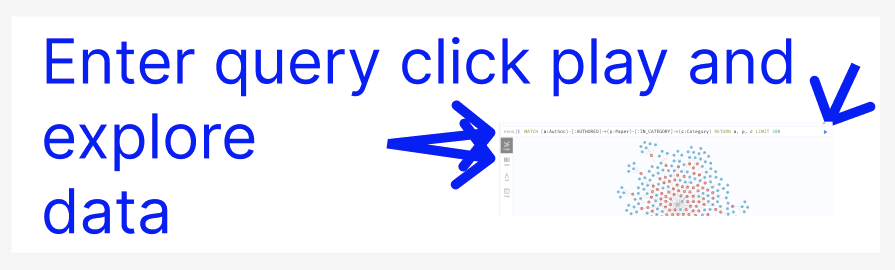
- Try another using the "where" clause to limit to "CS" papers:

`
    MATCH (a:Author)-[:AUTHORED]->(p:Paper)-[:IN_CATEGORY]->(c:Category)  
    RETURN a, p, c limit 50  
    union all  
    MATCH (a:Author)-[:AUTHORED]->(p:Paper)-[:IN_CATEGORY]->(c:Category)   
    where c.category starts with "cs"  
    RETURN a, p, c limit 50  
`
 - Try dragging the center node around :)
 - Explain to someone what this query asks and show them what the resulting graph looks like:
`
    MATCH (c:Category)--(p2:Paper)--(a2:Author)--(p3:Paper)--(c2:Category)
    where c<>c2
    RETURN c,p2,a2,p3,c2 limit 300
`

In [15]:
# (Run this and read to understand)
# List the count of papers in each category!

query_string = '''
MATCH (c:Category)
RETURN c.category, apoc.node.degree(c, "<IN_CATEGORY") AS inDegree
ORDER BY inDegree DESC LIMIT 20
'''

top_cat_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
top_cat_df.head(20)

,c.category,inDegree
0,astro-ph,19697
1,hep-ph,9506
2,hep-th,8857
3,quant-ph,6279
4,gr-qc,5282
5,cond-mat.mtrl-sci,4553
6,cond-mat.stat-mech,4380
7,cond-mat.str-el,4344
8,math.MP,4334
9,math-ph,4334


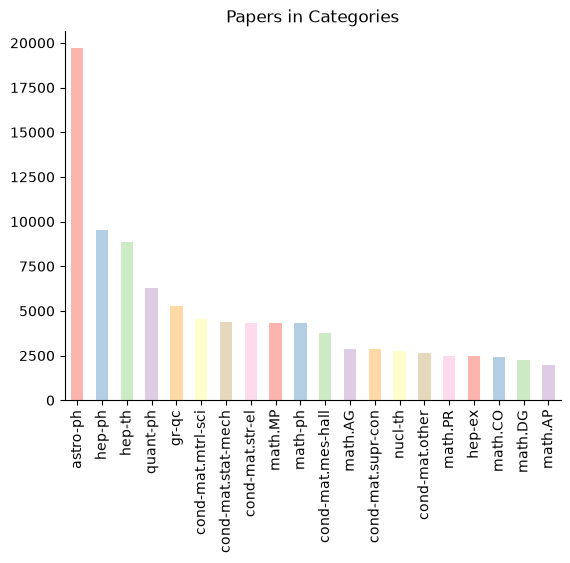

In [16]:
# (Run this and read to understand)
# Graph it in a bar plot
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colormaps
top_cat_df.plot.bar(y = "inDegree", x = "c.category", xlabel="", title="Papers in Categories", legend=None, color=plt.cm.Pastel1(np.arange(8)))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
# Can you show the indegree of just computer science type category papers?

# YOUR CODE HERE




,count(p)
0,100000


In [26]:
# Write an aggregate query to count all papers
# https://neo4j.com/docs/cypher-manual/current/functions/aggregating/

# YOUR CODE HERE

query_string = '''
MATCH (p:Paper) RETURN count(p)
'''

df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
df


,count(p)
0,100000


In [23]:
# Write a query to sum or count the total number of papers in CS type categories

# YOUR CODE HERE

query_string = '''
MATCH (p:Paper)-[:IN_CATEGORY]->(c:Category)
WHERE c.category STARTS WITH "cs."
RETURN count(DISTINCT p) AS total
'''

df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
df





,total
0,5812


In [33]:
# my query: Co-author pairs: which two authors wrote together most often? (two AUTHORED arrows pointing into the same paper)

query_string = '''
MATCH (a1:Author)-[:AUTHORED]->(p:Paper)<-[:AUTHORED]-(a2:Author)
WHERE a1.name < a2.name
RETURN a1.name, a2.name, count(p) AS collaboration_count
ORDER BY collaboration_count DESC
LIMIT 10
'''

df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
df


,a1.name,a2.name,collaboration_count
0,The BABAR Collaboration,B. Aubert,115
1,Damien Chablat,Philippe Wenger,70
2,D0 Collaboration,V. Abazov,50
3,CDF Collaboration,T. Aaltonen,44
4,G. F. Chen,N. L. Wang,42
5,M. Mayor,S. Udry,39
6,J. L. Luo,N. L. Wang,39
7,G. F. Chen,J. L. Luo,38
8,D. Queloz,S. Udry,37
9,D. Queloz,M. Mayor,35
